# Shipping Performance Analysis

As mentioned in the initial analysis, delivery questions will be measured per order. Therefore, for these questions rows with duplicate IDs will be dropped.

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

df = pd.read_csv('../data/processed/dataset.csv', parse_dates=['order_date', 'shipping_date'])

df = df.drop_duplicates('order_id')

## What percentage of orders are delivered early, on time, or late?

In [3]:
delivery_percentage = df['delivery_status'].value_counts(normalize=True) * 100

for status, percentage in delivery_percentage.items():
    print(f'{status}: {np.around(percentage, 2)}%')

Late delivery: 57.31%
Advance shipping: 24.05%
Shipping on time: 18.64%


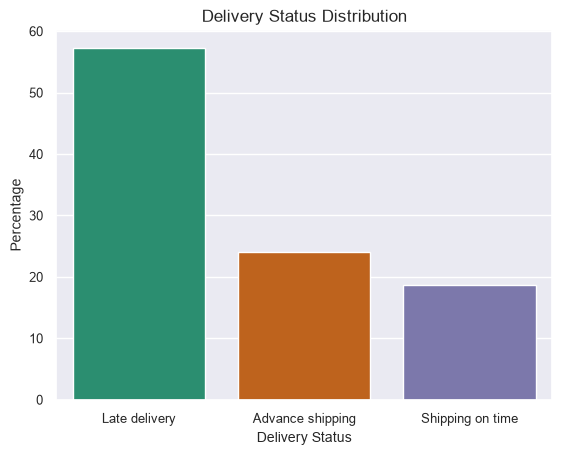

In [7]:
sns.barplot(x=delivery_percentage.index, y=delivery_percentage.values, hue=delivery_percentage.index, legend=False, palette='Dark2')

plt.title('Delivery Status Distribution')
plt.xlabel('Delivery Status', fontsize=10)
plt.ylabel('Percentage', fontsize=10)

plt.tick_params(axis='both', labelsize=9)

plt.show()

## Which shipping modes have the highest late-delivery rates?

In [10]:
shipping_mode_delivery = (
    df.assign(is_late=df['delivery_status'] == 'Late delivery')
    .groupby('shipping_mode')['is_late']
    .mean().sort_values(ascending=False) * 100

)

for status, percentage in shipping_mode_delivery.items():
    print(f'{status}: {np.around(percentage, 2)}%')

First Class: 100.0%
Second Class: 79.99%
Same Day: 48.37%
Standard Class: 39.85%


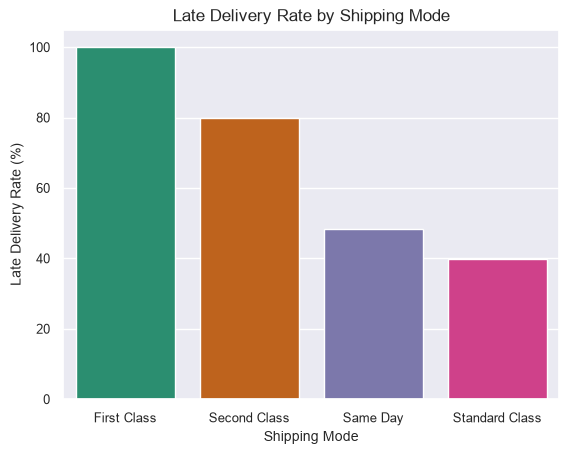

In [11]:
sns.barplot(x=shipping_mode_delivery.index, y=shipping_mode_delivery.values, hue=shipping_mode_delivery.index, legend=False, palette='Dark2')

plt.title('Late Delivery Rate by Shipping Mode')
plt.xlabel('Shipping Mode', fontsize=10)
plt.ylabel('Late Delivery Rate (%)', fontsize=10)

plt.tick_params(axis='both', labelsize=9)

plt.show()